In [ ]:
#1 — Setup

In [3]:
import os
import re
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import (ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import (KFold, RandomizedSearchCV, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")

# ---- Configuration ------------------------------------------------
DATA_PATH = "usedCars.csv"      # path to the dataset
REFERENCE_YEAR = 2026           # year used to compute car age
RANDOM_STATE = 42
OUTPUT_DIR = "outputs"          # model, tables and Power BI data are saved here
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# ---- Plot style ------------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"primary": "#0B6E4F", "accent": "#F2A541", "dark": "#1B2A41", "grey": "#8D99AE", "red": "#D1495B"}
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})


def save_show(name):
    """Tidy the layout, save the figure to outputs/figures and display it."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
#2 — Load and inspect the data

In [4]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())

Shape: (1064, 19)


,Id,Company,Model,Variant,FuelType,Colour,Kilometer,BodyStyle,TransmissionType,ManufactureDate,ModelYear,CngKit,Price,Owner,DealerState,DealerName,City,Warranty,QualityScore
0,555675,MARUTI SUZUKI,CELERIO(2017-2019),1.0 ZXI AMT O,PETROL,Silver,33197,HATCHBACK,NaN,01-02-2018,2018,NaN,5.75 Lakhs,1st Owner,Karnataka,Top Gear Cars,Bangalore,1,7.8
1,556383,MARUTI SUZUKI,ALTO,LXI,PETROL,Red,10322,HATCHBACK,Manual,01-03-2021,2021,NaN,4.35 Lakhs,1st Owner,Karnataka,Renew 4 u Automobiles PVT Ltd,Bangalore,1,8.3
2,556422,HYUNDAI,GRAND I10,1.2 KAPPA ASTA,PETROL,Grey,37889,HATCHBACK,Manual,01-03-2015,2015,NaN,4.7 Lakhs,1st Owner,Karnataka,Anant Cars Auto Pvt Ltd,Bangalore,1,7.9
3,556771,TATA,NEXON,XT PLUS,PETROL,A Blue,13106,HATCHBACK,NaN,01-08-2020,2020,NaN,9.9 Lakhs,1st Owner,Karnataka,Adeep Motors,Bangalore,1,8.1
4,559619,FORD,FIGO,EXI DURATORQ 1.4,DIESEL,Silver,104614,HATCHBACK,Manual,01-11-2010,2010,NaN,2.7 Lakhs,2nd Owner,Karnataka,Zippy Automart,Bangalore,0,7.5


In [5]:
print("Data types & non-null counts")
raw.info()

Data types & non-null counts
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1064 entries, 0 to 1063
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Id                1064 non-null   int64  
 1   Company           1064 non-null   object 
 2   Model             1064 non-null   object 
 3   Variant           1064 non-null   object 
 4   FuelType          1063 non-null   object 
 5   Colour            1064 non-null   object 
 6   Kilometer         1064 non-null   int64  
 7   BodyStyle         1064 non-null   object 
 8   TransmissionType  350 non-null    object 
 9   ManufactureDate   1064 non-null   object 
 10  ModelYear         1064 non-null   int64  
 11  CngKit            22 non-null     object 
 12  Price             1064 non-null   object 
 13  Owner             1064 non-null   object 
 14  DealerState       1064 non-null   object 
 15  DealerName        1064 non-null   object 
 16  City         

In [6]:
print("Missing values per column")
missing = raw.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(raw) * 100).round(1)
display(missing[missing["missing"] > 0])
print("Duplicate rows (excluding Id):", raw.drop(columns="Id").duplicated().sum())

Missing values per column


,missing,pct
FuelType,1,0.1
TransmissionType,714,67.1
CngKit,1042,97.9


Duplicate rows (excluding Id): 0


In [7]:
#3 — Data cleaning & feature engineering

In [8]:
LUXURY_BRANDS = {"MERCEDES BENZ", "BMW", "AUDI", "VOLVO"}
AUTO_PATTERN = r"\b(?:AMT|AT|CVT|DSG|DCT|AGS|TCT|AUTOMATIC|AUTO|TIPTRONIC|S[- ]?TRONIC)\b"
COLOUR_KEYWORDS = [("white", "White"), ("silver", "Silver"), ("grey", "Grey"), ("gray", "Grey"),
                   ("gun", "Grey"), ("steel", "Grey"), ("black", "Black"), ("red", "Red"),
                   ("maroon", "Red"), ("cherry", "Red"), ("blue", "Blue"), ("aqua", "Blue"), ("brown", "Brown"),
                   ("beige", "Brown"), ("bronze", "Brown"), ("titanium", "Grey"), ("orange", "Orange"),
                   ("gold", "Gold"), ("green", "Green"), ("forest", "Green"), ("yellow", "Yellow")]


def parse_price(value):
    """'5.75 Lakhs' -> 5.75 ; '95,000' (plain rupees) -> 0.95 ; returns price in INR Lakhs."""
    s = str(value).lower().replace(",", "").strip()
    number = float(re.findall(r"[\d.]+", s)[0])
    if "crore" in s:
        return number * 100
    if "lakh" in s:
        return number
    return number / 100_000


def clean_transmission(raw_value, variant):
    """Standardise spelling; if missing, infer from the variant name (AMT/CVT/DSG... = automatic)."""
    t = str(raw_value).strip().upper() if pd.notna(raw_value) else ""
    if t in ("MANUAL", "M"):
        return "Manual"
    if t in ("AUTOMATIC", "AUOTMATIC", "A", "CVT"):
        return "Automatic"
    return "Automatic" if re.search(AUTO_PATTERN, str(variant).upper()) else "Manual"


def colour_group(colour):
    c = str(colour).lower()
    for key, group in COLOUR_KEYWORDS:
        if key in c:
            return group
    return "Other"


def clean_and_engineer(raw_df):
    """Clean raw columns and create new features. Returns a new DataFrame."""
    d = raw_df.copy()

    # --- target ---------------------------------------------------------------------
    d["Price_Lakhs"] = d["Price"].apply(parse_price)

    # --- categorical clean-up -----------------------------------------------------
    d["FuelType"] = d["FuelType"].fillna("PETROL").str.strip().str.upper()          # 1 missing -> most common
    d["FuelType"] = d["FuelType"].replace({"HYBRID": "OTHER", "LPG": "OTHER"}).str.title()
    d["FuelType"] = d["FuelType"].replace({"Cng": "CNG"})
    d["BodyStyle"] = (d["BodyStyle"].str.strip().str.upper()
                      .replace({"COMPACTSUV": "SUV", "MUV": "MPV"}).str.title()
                      .replace({"Suv": "SUV", "Mpv": "MPV"}))
    d["Transmission"] = [clean_transmission(t, v) for t, v in zip(d["TransmissionType"], d["Variant"])]
    d["Model_Clean"] = d["Model"].str.replace(r"\(.*?\)", "", regex=True).str.strip()
    d["ColourGroup"] = d["Colour"].apply(colour_group)
    d["Owner_Num"] = d["Owner"].str.extract(r"(\d)")[0].astype(int)
    d["HasCng"] = d["CngKit"].notna().astype(int)                                   # NaN means "no CNG kit"

    # --- numeric clean-up ----------------------------------------------------------
    d["Kilometer"] = d["Kilometer"].clip(upper=250_000)                             # cap extreme / typo readings
    d["QualityScore"] = d["QualityScore"].replace(0, np.nan)                        # 0.0 = not scored

    # --- feature engineering -------------------------------------------------------
    d["ManufactureDate"] = pd.to_datetime(d["ManufactureDate"], format="%d-%m-%Y", errors="coerce")
    d["Age"] = REFERENCE_YEAR - d["ModelYear"]                                       # car age in years
    d["KmPerYear"] = d["Kilometer"] / d["Age"].clip(lower=1)                         # usage intensity
    d["IsAutomatic"] = (d["Transmission"] == "Automatic").astype(int)
    d["IsLuxury"] = d["Company"].isin(LUXURY_BRANDS).astype(int)
    disp = d["Variant"].str.extract(r"(?<![\d.])([1-6]\.\d)(?![\d])")[0].astype(float)  # engine size in litres
    d["Displacement"] = disp.where(disp.between(0.6, 6.0))
    return d


df = clean_and_engineer(raw)
print("Clean shape:", df.shape)
print("Missing after cleaning (engineered/used columns):")
print(df[["Price_Lakhs", "Age", "Kilometer", "QualityScore", "Displacement"]].isna().sum())

Clean shape: (1064, 30)
Missing after cleaning (engineered/used columns):
Price_Lakhs       0
Age               0
Kilometer         0
QualityScore      2
Displacement    534
dtype: int64


In [9]:
df["Price_Segment"] = pd.cut(df["Price_Lakhs"], [0, 5, 10, 20, np.inf],
                             labels=["Budget (<5L)", "Mid (5-10L)", "Premium (10-20L)", "Luxury (>20L)"])
df["Age_Band"] = pd.cut(df["Age"], [-1, 3, 6, 10, 30], labels=["0-3 yrs", "4-6 yrs", "7-10 yrs", "10+ yrs"])
df["Km_Band"] = pd.cut(df["Kilometer"], [-1, 20_000, 50_000, 80_000, 1e9],
                       labels=["<20k", "20-50k", "50-80k", "80k+"])

print("Unmapped colours:", sorted(df.loc[df["ColourGroup"] == "Other", "Colour"].unique())[:15])
display(df[["Company", "Model_Clean", "Age", "Kilometer", "Transmission", "FuelType", "City", "Price_Lakhs"]].head())
display(df["Price_Lakhs"].describe().round(2).to_frame().T)

Unmapped colours: ['B Mist', 'Chill', 'Dust', 'Metallic', 'Other', 'Purple', 'W B Mist', 'other']


,Company,Model_Clean,Age,Kilometer,Transmission,FuelType,City,Price_Lakhs
0,MARUTI SUZUKI,CELERIO,8,33197,Automatic,Petrol,Bangalore,5.75
1,MARUTI SUZUKI,ALTO,5,10322,Manual,Petrol,Bangalore,4.35
2,HYUNDAI,GRAND I10,11,37889,Manual,Petrol,Bangalore,4.70
3,TATA,NEXON,6,13106,Manual,Petrol,Bangalore,9.90
4,FORD,FIGO,16,104614,Manual,Diesel,Bangalore,2.70


,count,mean,std,min,25%,50%,75%,max
Price_Lakhs,1064.0,8.35,5.73,0.95,4.85,6.75,9.85,85.0


In [10]:
#4 — EDA: target distribution

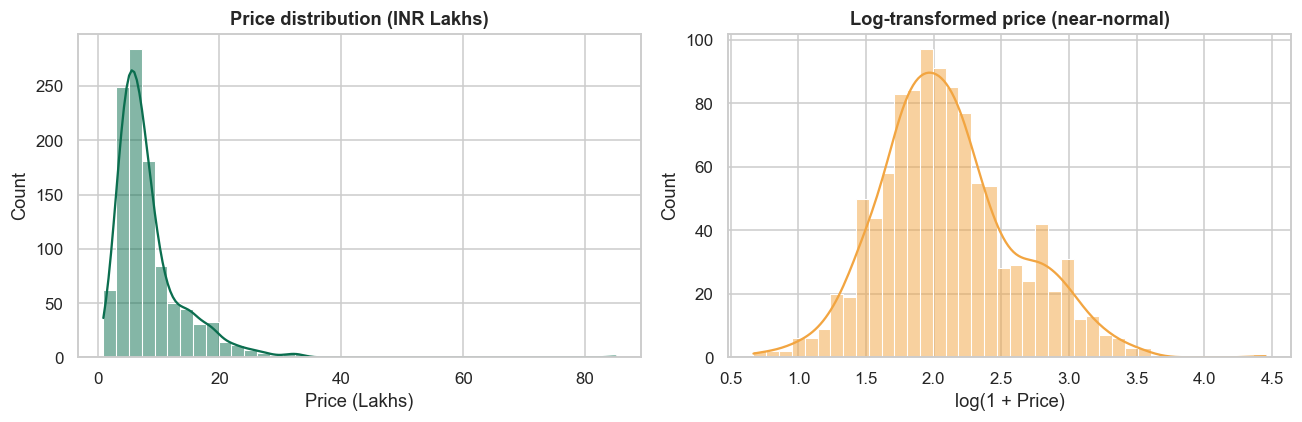

Skewness: raw = 3.55  |  log = 0.44


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price_Lakhs"], bins=40, kde=True, color=PALETTE["primary"], ax=ax[0])
ax[0].set(title="Price distribution (INR Lakhs)", xlabel="Price (Lakhs)")
sns.histplot(np.log1p(df["Price_Lakhs"]), bins=40, kde=True, color=PALETTE["accent"], ax=ax[1])
ax[1].set(title="Log-transformed price (near-normal)", xlabel="log(1 + Price)")
save_show("01_price_distribution")
print(f"Skewness: raw = {df['Price_Lakhs'].skew():.2f}  |  log = {np.log1p(df['Price_Lakhs']).skew():.2f}")

In [12]:
#5 — EDA: brand and city

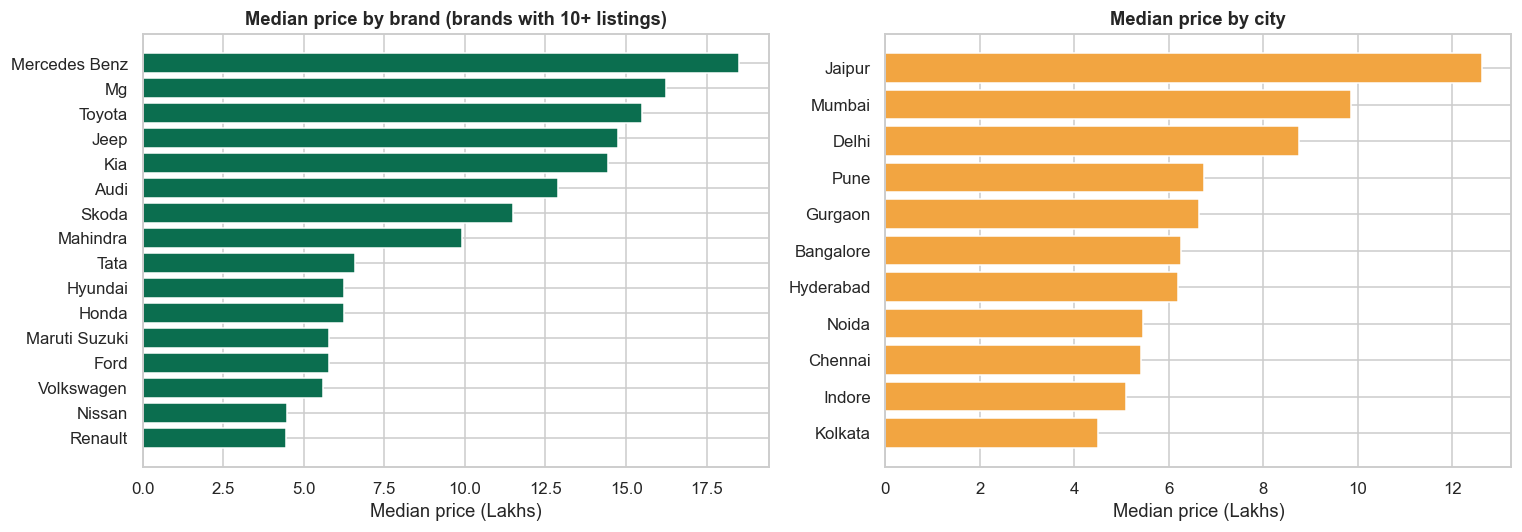

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
top_brands = df.groupby("Company")["Price_Lakhs"].agg(["median", "count"]).query("count >= 10").sort_values("median")
ax[0].barh(top_brands.index.str.title(), top_brands["median"], color=PALETTE["primary"])
ax[0].set(title="Median price by brand (brands with 10+ listings)", xlabel="Median price (Lakhs)")

city = df.groupby("City")["Price_Lakhs"].median().sort_values()
ax[1].barh(city.index, city.values, color=PALETTE["accent"])
ax[1].set(title="Median price by city", xlabel="Median price (Lakhs)")
save_show("02_brand_city_price")

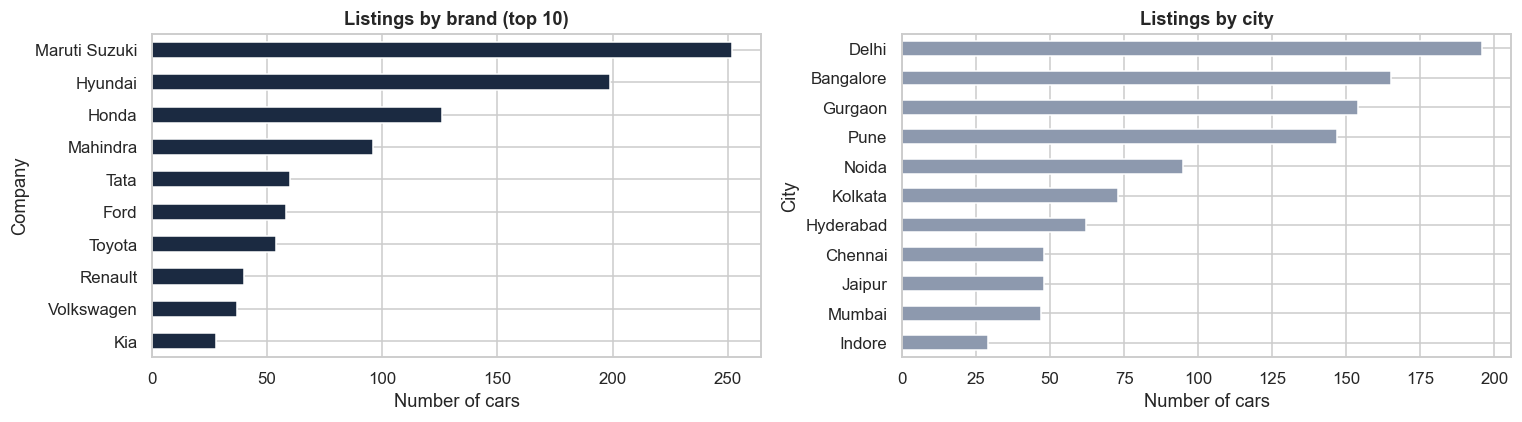

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df["Company"].str.title().value_counts().head(10).sort_values().plot.barh(color=PALETTE["dark"], ax=ax[0])
ax[0].set(title="Listings by brand (top 10)", xlabel="Number of cars")
df["City"].value_counts().sort_values().plot.barh(color=PALETTE["grey"], ax=ax[1])
ax[1].set(title="Listings by city", xlabel="Number of cars")
save_show("03_inventory_mix")

In [15]:
#6 — EDA: age & mileage

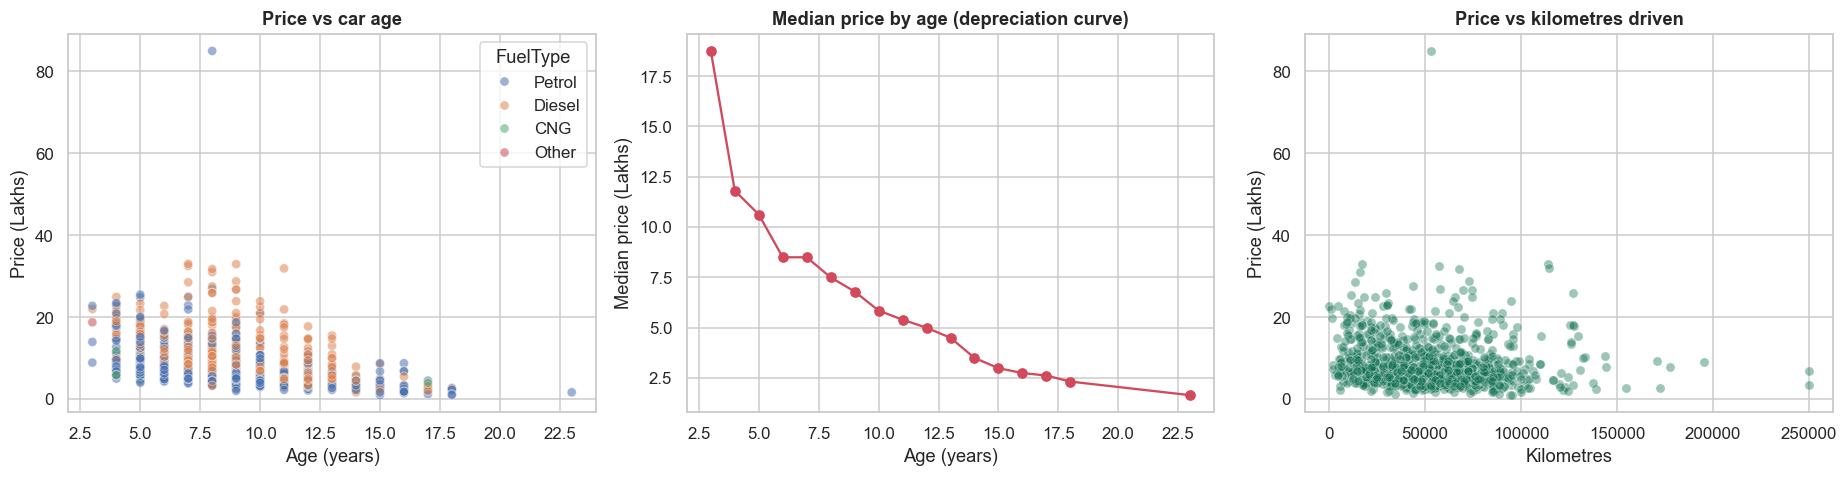

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="Age", y="Price_Lakhs", hue="FuelType", alpha=0.55, ax=ax[0])
ax[0].set(title="Price vs car age", xlabel="Age (years)", ylabel="Price (Lakhs)")

med_age = df.groupby("Age")["Price_Lakhs"].median()
ax[1].plot(med_age.index, med_age.values, marker="o", color=PALETTE["red"])
ax[1].set(title="Median price by age (depreciation curve)", xlabel="Age (years)", ylabel="Median price (Lakhs)")

sns.scatterplot(data=df, x="Kilometer", y="Price_Lakhs", alpha=0.4, color=PALETTE["primary"], ax=ax[2])
ax[2].set(title="Price vs kilometres driven", xlabel="Kilometres", ylabel="Price (Lakhs)")
save_show("04_age_km_vs_price")

In [17]:
#7 — EDA: categorical drivers

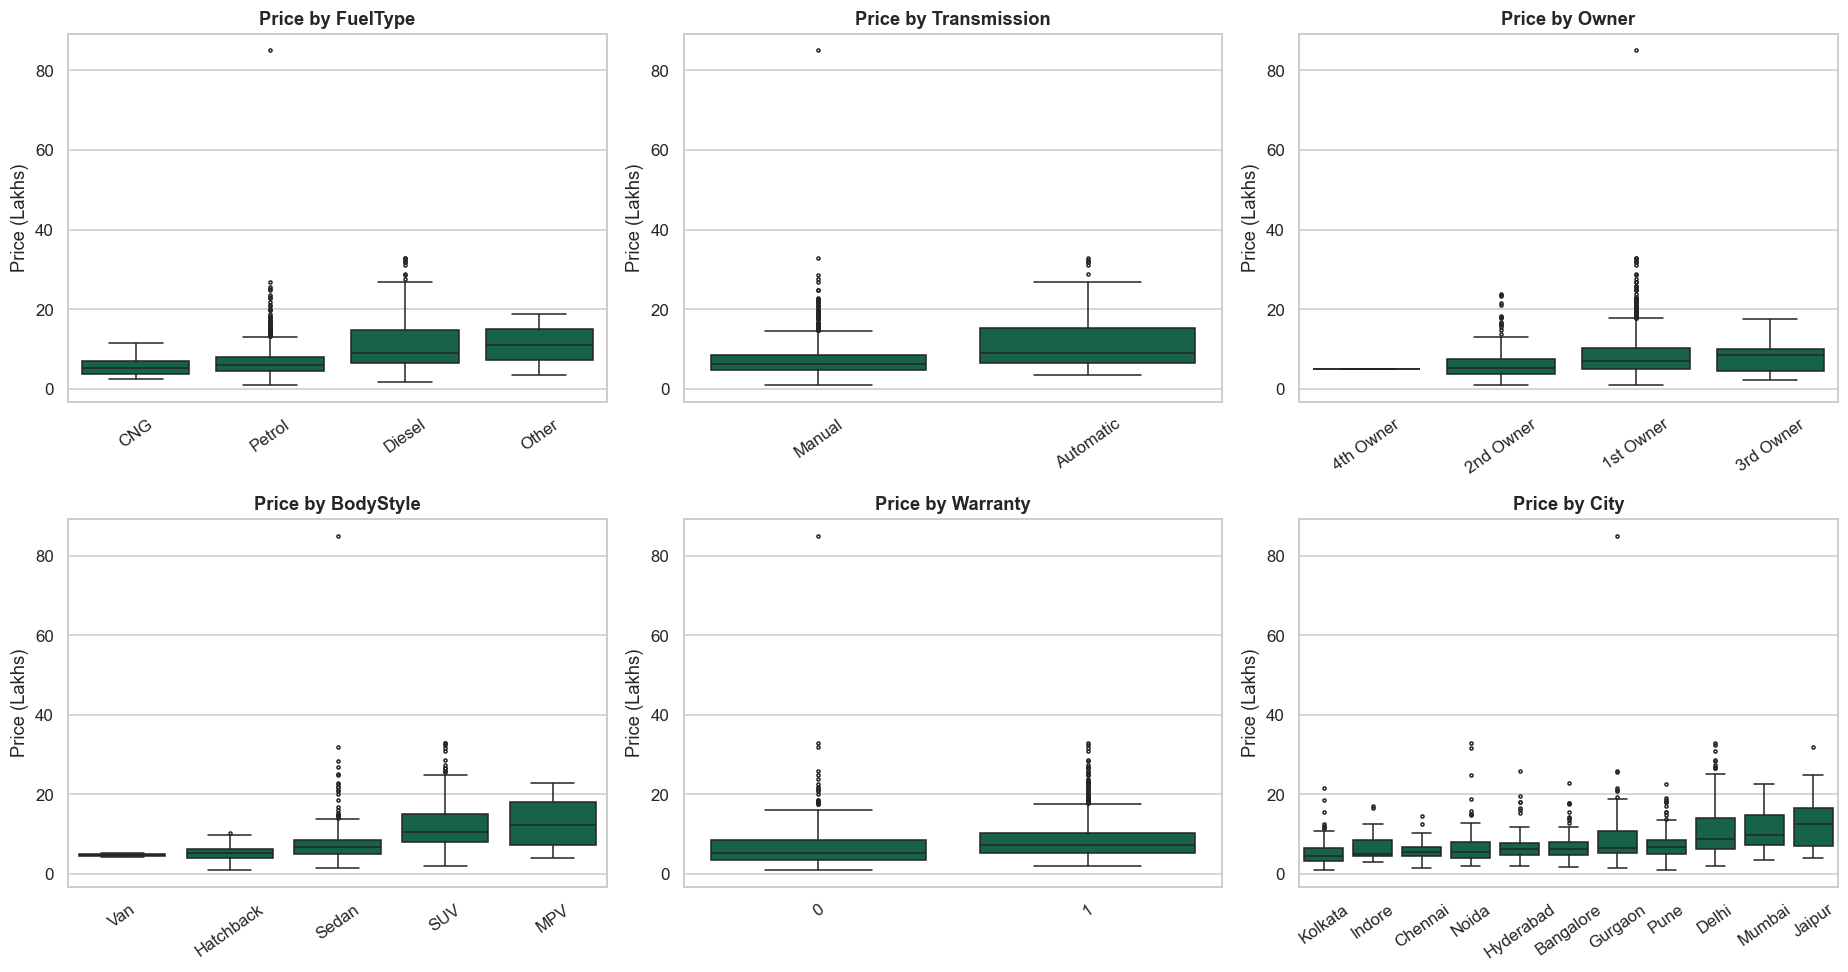

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.ravel(), ["FuelType", "Transmission", "Owner", "BodyStyle", "Warranty", "City"]):
    order = df.groupby(col)["Price_Lakhs"].median().sort_values().index
    sns.boxplot(data=df, x=col, y="Price_Lakhs", order=order, color=PALETTE["primary"], fliersize=2, ax=ax)
    ax.set(title=f"Price by {col}", xlabel="", ylabel="Price (Lakhs)")
    ax.tick_params(axis="x", rotation=35)
save_show("05_categorical_boxplots")

In [19]:
#8 — EDA: correlation heatmap

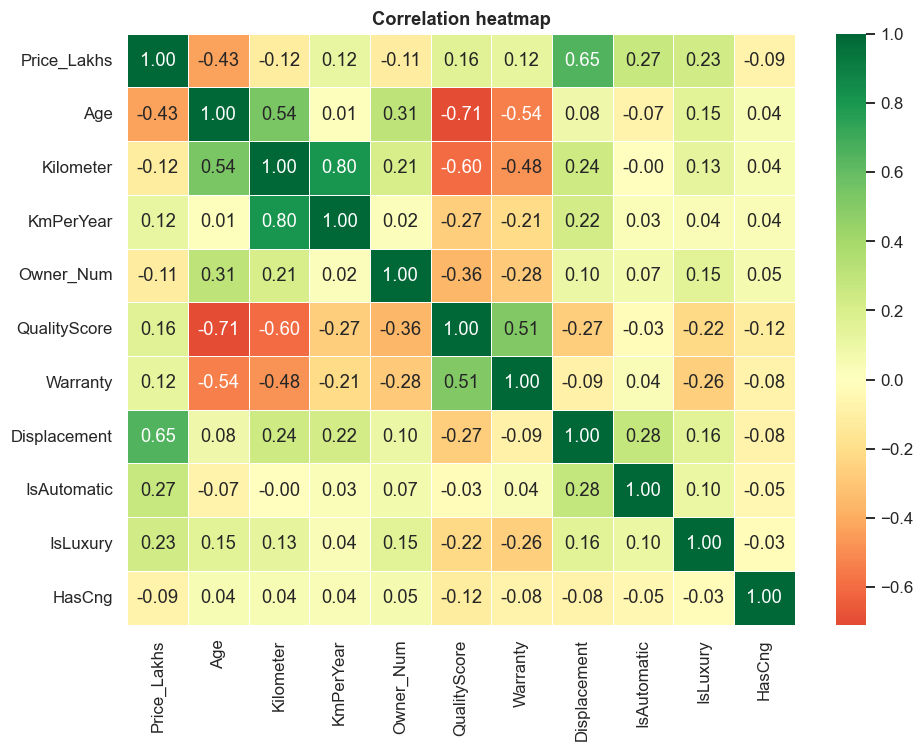

Correlation with price:
 Age            -0.43
Kilometer      -0.12
Owner_Num      -0.11
HasCng         -0.09
KmPerYear       0.12
Warranty        0.12
QualityScore    0.16
IsLuxury        0.23
IsAutomatic     0.27
Displacement    0.65
Name: Price_Lakhs, dtype: float64


In [20]:
num_cols = ["Price_Lakhs", "Age", "Kilometer", "KmPerYear", "Owner_Num", "QualityScore",
            "Warranty", "Displacement", "IsAutomatic", "IsLuxury", "HasCng"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdYlGn", center=0, linewidths=0.5)
plt.title("Correlation heatmap")
save_show("06_correlation_heatmap")

corr_price = df[num_cols].corr()["Price_Lakhs"].drop("Price_Lakhs").sort_values()
print("Correlation with price:\n", corr_price.round(2))

In [21]:
#9 — Train/test split + preprocessing pipeline

In [22]:
NUM_FEATURES = ["Age", "Kilometer", "KmPerYear", "Owner_Num", "QualityScore", "Warranty",
                "Displacement", "IsAutomatic", "IsLuxury", "HasCng"]
OHE_FEATURES = ["FuelType", "BodyStyle", "ColourGroup", "City"]
TE_FEATURES = ["Company", "Model_Clean"]
FEATURES = NUM_FEATURES + OHE_FEATURES + TE_FEATURES
TARGET = "Price_Lakhs"

X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")


def build_preprocessor():
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    onehot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
    target_enc = TargetEncoder(target_type="continuous", random_state=RANDOM_STATE)
    return ColumnTransformer([
        ("num", numeric, NUM_FEATURES),
        ("ohe", onehot, OHE_FEATURES),
        ("te", target_enc, TE_FEATURES),
    ])


def make_model(estimator):
    """Full pipeline: preprocessing -> estimator, trained on log(price), predicting in Lakhs."""
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", build_preprocessor()), ("model", estimator)]),
        func=np.log1p, inverse_func=np.expm1)


def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred), "MAPE_%": mean_absolute_percentage_error(y_true, y_pred) * 100}

Train: (851, 16)  |  Test: (213, 16)


In [23]:
#10 — Compare 9 regression algorithms

In [27]:
candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.001, max_iter=20000),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=7, weights="distance"),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=3, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=1, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   subsample=0.8, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "mse": "neg_mean_squared_error"}
rows, fitted = [], {}

for name, est in candidates.items():
    model = make_model(est)
    cvres = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    model.fit(X_train, y_train)
    m = evaluate(y_test, model.predict(X_test))
    fitted[name] = model
    rows.append({"Model": name, "CV_R2": cvres["test_r2"].mean(), "CV_MAE": -cvres["test_mae"].mean(),
                 "Test_MSE": m["MSE"], "Test_RMSE": m["RMSE"], "Test_MAE": m["MAE"],
                 "Test_R2": m["R2"], "Test_MAPE_%": m["MAPE_%"]})
    print(f"{name:<24} CV R2 = {rows[-1]['CV_R2']:.3f} | Test R2 = {m['R2']:.3f} | Test MAE = {m['MAE']:.2f} L")

results = pd.DataFrame(rows).sort_values("CV_R2", ascending=False).reset_index(drop=True)
display(results.round(3))

Linear Regression        CV R2 = 0.711 | Test R2 = 0.811 | Test MAE = 1.27 L
Ridge Regression         CV R2 = 0.711 | Test R2 = 0.812 | Test MAE = 1.27 L
Lasso Regression         CV R2 = 0.713 | Test R2 = 0.808 | Test MAE = 1.26 L
KNN Regressor            CV R2 = 0.625 | Test R2 = 0.689 | Test MAE = 1.71 L
Decision Tree            CV R2 = 0.640 | Test R2 = 0.790 | Test MAE = 1.52 L
Random Forest            CV R2 = 0.701 | Test R2 = 0.835 | Test MAE = 1.17 L
Extra Trees              CV R2 = 0.698 | Test R2 = 0.830 | Test MAE = 1.19 L
Gradient Boosting        CV R2 = 0.726 | Test R2 = 0.835 | Test MAE = 1.15 L
Hist Gradient Boosting   CV R2 = 0.712 | Test R2 = 0.838 | Test MAE = 1.21 L


,Model,CV_R2,CV_MAE,Test_MSE,Test_RMSE,Test_MAE,Test_R2,Test_MAPE_%
0,Gradient Boosting,0.726,1.349,3.955,1.989,1.151,0.835,13.922
1,Lasso Regression,0.713,1.395,4.588,2.142,1.261,0.808,15.634
2,Hist Gradient Boosting,0.712,1.419,3.887,1.971,1.215,0.838,14.854
3,Ridge Regression,0.711,1.410,4.509,2.123,1.270,0.812,15.820
4,Linear Regression,0.711,1.415,4.517,2.125,1.270,0.811,15.819
5,Random Forest,0.701,1.473,3.943,1.986,1.168,0.835,14.221
6,Extra Trees,0.698,1.411,4.057,2.014,1.187,0.830,14.286
7,Decision Tree,0.640,1.764,5.025,2.242,1.516,0.790,19.497
8,KNN Regressor,0.625,1.866,7.444,2.728,1.711,0.689,20.906


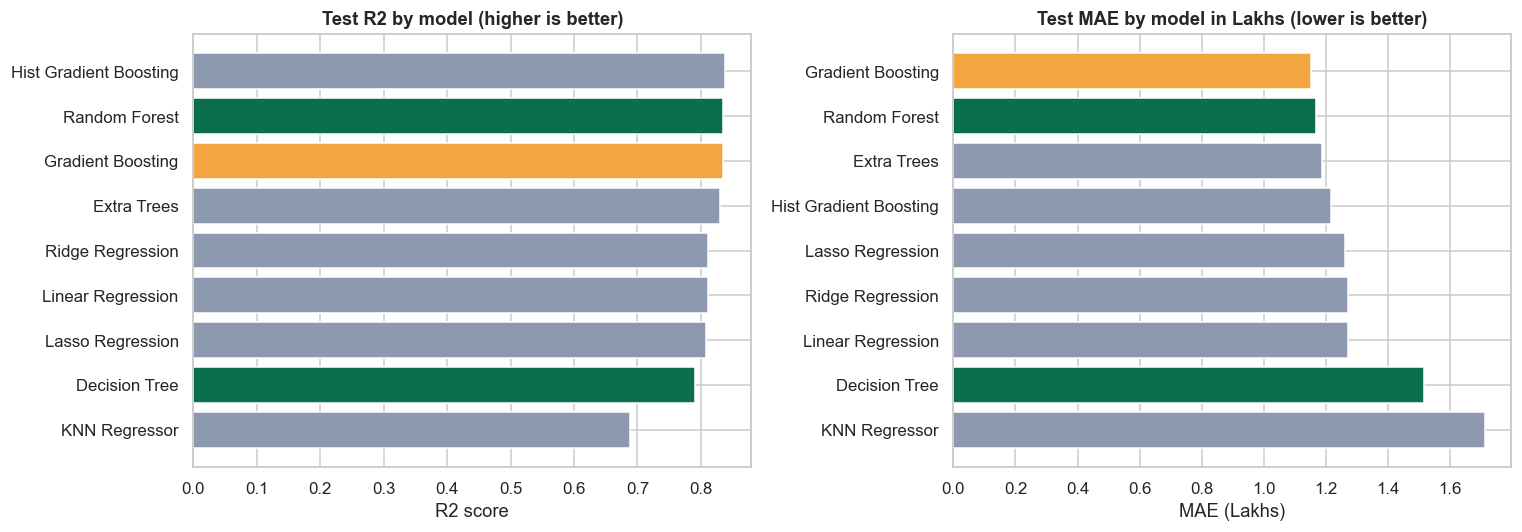

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
best_cv = results.loc[0, "Model"]                       # best model on cross-validated R2


def bar_colors(names):
    """Green = required Decision Tree / Random Forest, orange = best model, grey = others."""
    return [PALETTE["accent"] if m == best_cv else PALETTE["primary"] if m in ("Random Forest", "Decision Tree")
            else PALETTE["grey"] for m in names]


order = results.sort_values("Test_R2")
ax[0].barh(order["Model"], order["Test_R2"], color=bar_colors(order["Model"]))
ax[0].set(title="Test R2 by model (higher is better)", xlabel="R2 score")
order = results.sort_values("Test_MAE", ascending=False)
ax[1].barh(order["Model"], order["Test_MAE"], color=bar_colors(order["Model"]))
ax[1].set(title="Test MAE by model in Lakhs (lower is better)", xlabel="MAE (Lakhs)")
save_show("07_model_comparison")

In [29]:
#11 — Hyperparameter tuning

In [30]:
search_spaces = {
    "Random Forest": (RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE), {
        "regressor__model__n_estimators": [200, 300, 500, 700],
        "regressor__model__max_depth": [None, 10, 15, 20, 30],
        "regressor__model__min_samples_leaf": [1, 2, 3, 5],
        "regressor__model__max_features": ["sqrt", 0.5, 0.7, 1.0]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE), {
        "regressor__model__n_estimators": [200, 300, 500, 700],
        "regressor__model__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
        "regressor__model__max_depth": [2, 3, 4, 5],
        "regressor__model__subsample": [0.7, 0.8, 1.0],
        "regressor__model__min_samples_leaf": [1, 3, 5]}),
}

tuned = {}
for name, (est, grid) in search_spaces.items():
    rs = RandomizedSearchCV(make_model(est), grid, n_iter=20, cv=cv, scoring="neg_mean_absolute_error",
                            random_state=RANDOM_STATE, n_jobs=-1)
    rs.fit(X_train, y_train)
    tuned[name] = rs
    print(f"{name}: best CV MAE = {-rs.best_score_:.3f} L")
    print("   best params:", {k.split('__')[-1]: v for k, v in rs.best_params_.items()})

Random Forest: best CV MAE = 1.429 L
   best params: {'n_estimators': 700, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 15}
Gradient Boosting: best CV MAE = 1.314 L
   best params: {'subsample': 0.7, 'n_estimators': 500, 'min_samples_leaf': 3, 'max_depth': 3, 'learning_rate': 0.03}


In [31]:
#12 — Final model evaluation

In [32]:
# Pick the tuned model with the best cross-validated score (chosen on training data only)
best_name = max(tuned, key=lambda n: tuned[n].best_score_)
final_model = tuned[best_name].best_estimator_
print("Selected final model:", best_name)

pred_test = final_model.predict(X_test)
final_metrics = evaluate(y_test, pred_test)
print("\nFinal model – hold-out test performance")
for k, v in final_metrics.items():
    print(f"  {k:<7}: {v:,.3f}")

# Decision Tree vs Random Forest vs tuned final model (the required comparison)
compare = pd.DataFrame({
    "Decision Tree": evaluate(y_test, fitted["Decision Tree"].predict(X_test)),
    "Random Forest (default)": evaluate(y_test, fitted["Random Forest"].predict(X_test)),
    f"{best_name} (tuned)": final_metrics}).T
display(compare.round(3))

Selected final model: Gradient Boosting

Final model – hold-out test performance
  MSE    : 3.654
  RMSE   : 1.912
  MAE    : 1.129
  R2     : 0.847
  MAPE_% : 13.317


,MSE,RMSE,MAE,R2,MAPE_%
Decision Tree,5.025,2.242,1.516,0.790,19.497
Random Forest (default),3.943,1.986,1.168,0.835,14.221
Gradient Boosting (tuned),3.654,1.912,1.129,0.847,13.317


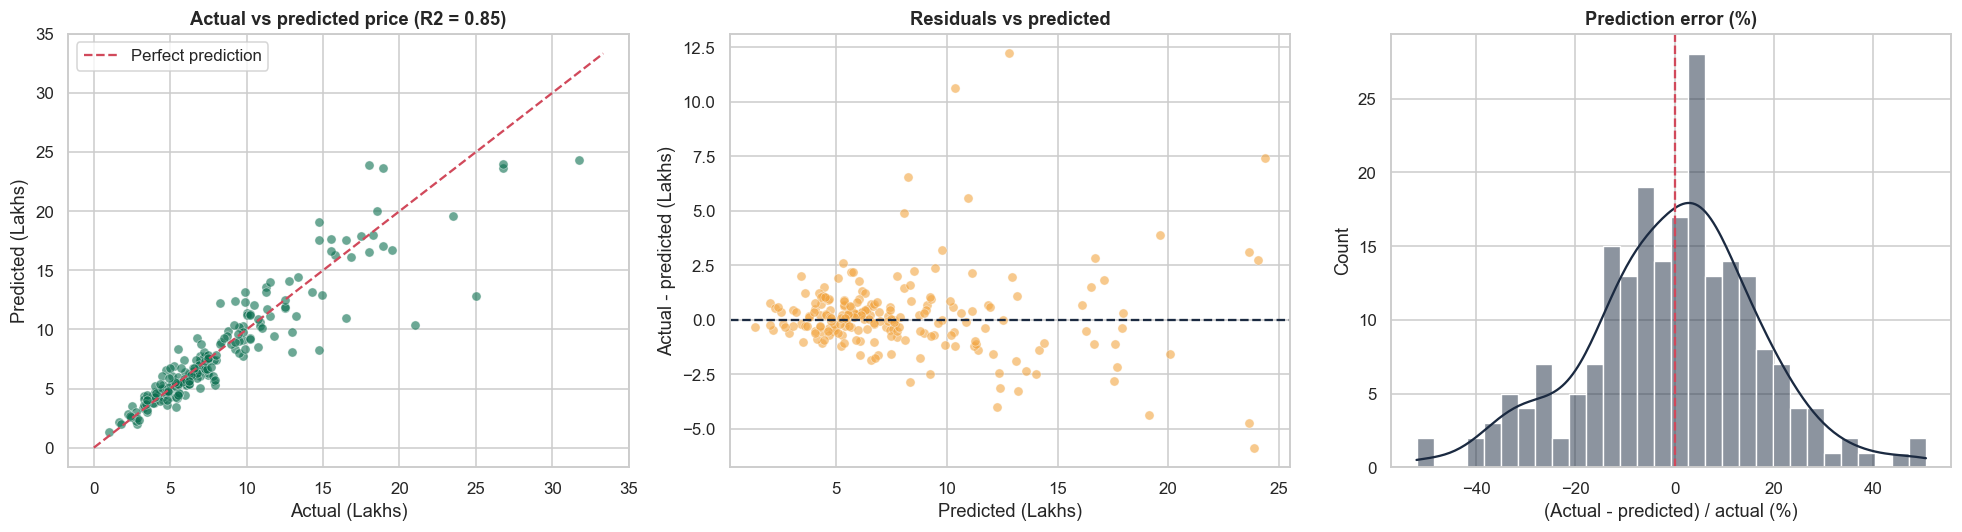

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Actual vs predicted
ax[0].scatter(y_test, pred_test, alpha=0.6, color=PALETTE["primary"], edgecolor="white", linewidth=0.4)
lims = [0, max(y_test.max(), pred_test.max()) * 1.05]
ax[0].plot(lims, lims, "--", color=PALETTE["red"], label="Perfect prediction")
ax[0].set(title=f"Actual vs predicted price (R2 = {final_metrics['R2']:.2f})", xlabel="Actual (Lakhs)", ylabel="Predicted (Lakhs)")
ax[0].legend()

# Residuals vs predicted
resid = y_test - pred_test
ax[1].scatter(pred_test, resid, alpha=0.6, color=PALETTE["accent"], edgecolor="white", linewidth=0.4)
ax[1].axhline(0, color=PALETTE["dark"], linestyle="--")
ax[1].set(title="Residuals vs predicted", xlabel="Predicted (Lakhs)", ylabel="Actual - predicted (Lakhs)")

# Percentage-error distribution
pct_err = (resid / y_test * 100).clip(-60, 60)
sns.histplot(pct_err, bins=30, kde=True, color=PALETTE["dark"], ax=ax[2])
ax[2].axvline(0, color=PALETTE["red"], linestyle="--")
ax[2].set(title="Prediction error (%)", xlabel="(Actual - predicted) / actual (%)")
save_show("08_final_model_diagnostics")

In [34]:
# Where does the model work best? Accuracy by price segment
seg = pd.DataFrame({"actual": y_test, "pred": pred_test})
seg["Segment"] = pd.cut(seg["actual"], [0, 5, 10, 20, np.inf], labels=["Budget (<5L)", "Mid (5-10L)", "Premium (10-20L)", "Luxury (>20L)"])
seg["abs_err"] = (seg["actual"] - seg["pred"]).abs()
seg["ape"] = seg["abs_err"] / seg["actual"] * 100
seg_summary = seg.groupby("Segment", observed=True).agg(cars=("actual", "size"), MAE_Lakhs=("abs_err", "mean"), MAPE_pct=("ape", "mean")).round(2)
display(seg_summary)
print(f"Share of test cars predicted within +/-10%: {(seg['ape'] <= 10).mean():.0%}   within +/-20%: {(seg['ape'] <= 20).mean():.0%}")

,cars,MAE_Lakhs,MAPE_pct
Segment,,,
Budget (<5L),54,0.56,15.58
Mid (5-10L),110,0.82,11.49
Premium (10-20L),43,1.87,13.26
Luxury (>20L),6,6.67,26.88


Share of test cars predicted within +/-10%: 50%   within +/-20%: 78%


In [35]:
#13 — Feature importance

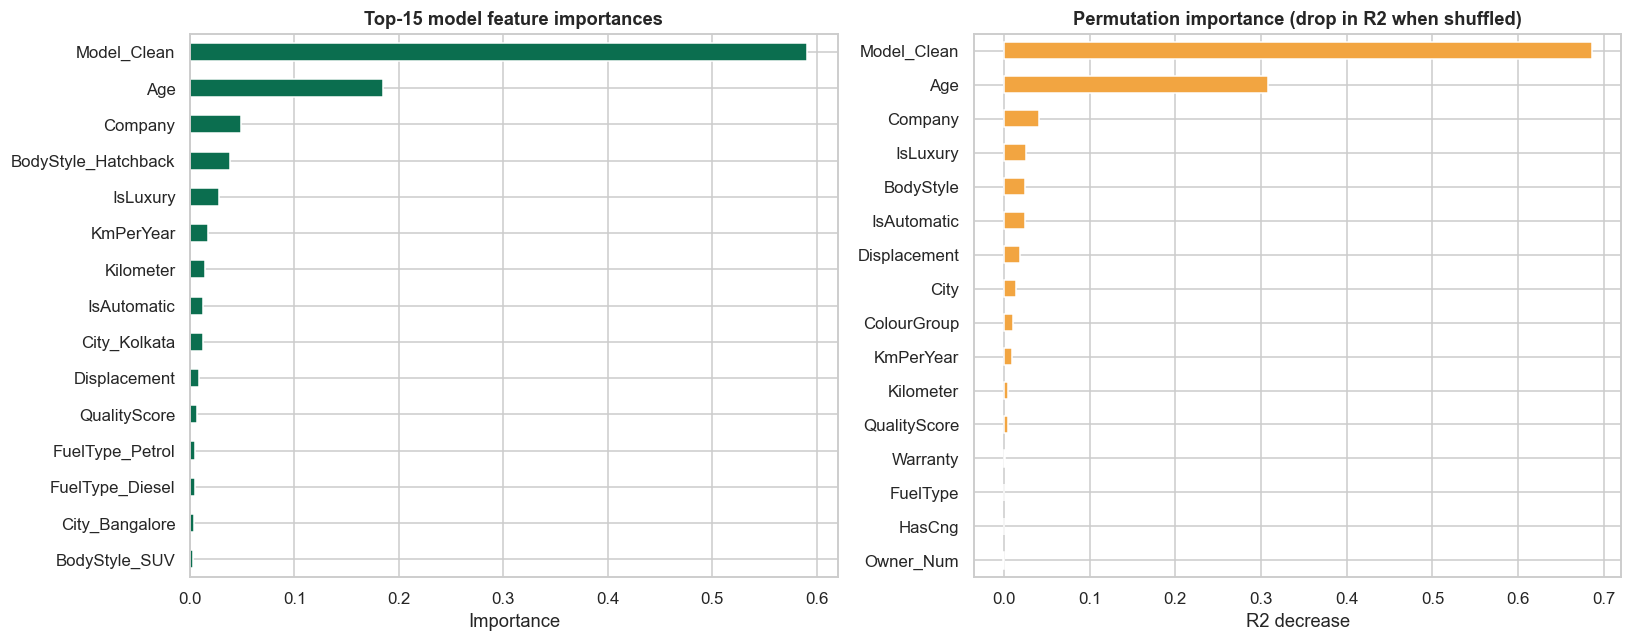

,permutation_importance
Model_Clean,0.686
Age,0.308
Company,0.040
IsLuxury,0.026
BodyStyle,0.025
IsAutomatic,0.024
Displacement,0.018
City,0.014
ColourGroup,0.011
KmPerYear,0.009


In [36]:
# (a) Built-in importance from the model 
prep = final_model.regressor_.named_steps["prep"]
est = final_model.regressor_.named_steps["model"]
feat_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
imp = pd.Series(est.feature_importances_, index=feat_names).sort_values(ascending=False)

# (b) Permutation importance on ORIGINAL columns 
perm = permutation_importance(final_model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
imp.head(15).sort_values().plot.barh(color=PALETTE["primary"], ax=ax[0])
ax[0].set(title="Top-15 model feature importances", xlabel="Importance")
perm_imp.sort_values().plot.barh(color=PALETTE["accent"], ax=ax[1])
ax[1].set(title="Permutation importance (drop in R2 when shuffled)", xlabel="R2 decrease")
save_show("09_feature_importance")
display(perm_imp.round(3).to_frame("permutation_importance").head(10))

In [37]:
#14 — Out-of-fold predictions + export for Power BI

In [38]:
oof_pred = cross_val_predict(final_model, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)

bi = df.copy()
bi["Predicted_Price_Lakhs"] = oof_pred.round(2)
bi["Error_Lakhs"] = (bi["Price_Lakhs"] - bi["Predicted_Price_Lakhs"]).round(2)
bi["Abs_Error_Lakhs"] = bi["Error_Lakhs"].abs()
bi["Abs_Pct_Error"] = (bi["Abs_Error_Lakhs"] / bi["Price_Lakhs"] * 100).round(1)
# Pricing recommendation flag: how does the listed price compare with the model's fair value?
bi["Price_vs_Market"] = np.select(
    [bi["Price_Lakhs"] > bi["Predicted_Price_Lakhs"] * 1.10, bi["Price_Lakhs"] < bi["Predicted_Price_Lakhs"] * 0.90],
    ["Above market (>10%)", "Below market (>10%)"], default="Fair (within 10%)")

# Sort-order helper columns so Power BI shows bands in the right order (not alphabetical)
bi["Age_Band_Sort"] = bi["Age_Band"].cat.codes + 1
bi["Km_Band_Sort"] = bi["Km_Band"].cat.codes + 1
bi["Price_Segment_Sort"] = bi["Price_Segment"].cat.codes + 1
bi["Price_vs_Market_Sort"] = bi["Price_vs_Market"].map(
    {"Below market (>10%)": 1, "Fair (within 10%)": 2, "Above market (>10%)": 3})

bi_cols = ["Id", "Company", "Model_Clean", "Variant", "FuelType", "Transmission", "BodyStyle", "ColourGroup",
           "Owner", "City", "DealerState", "Kilometer", "ModelYear", "Age", "Age_Band", "Age_Band_Sort",
           "Km_Band", "Km_Band_Sort", "Warranty", "QualityScore", "Price_Lakhs", "Price_Segment",
           "Price_Segment_Sort", "Predicted_Price_Lakhs", "Error_Lakhs", "Abs_Error_Lakhs",
           "Abs_Pct_Error", "Price_vs_Market", "Price_vs_Market_Sort"]
bi[bi_cols].to_csv(os.path.join(OUTPUT_DIR, "powerbi_dashboard_data.csv"), index=False)

# supporting tables
results.round(4).to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"), index=False)
pd.DataFrame({"Feature": perm_imp.index, "Permutation_Importance": perm_imp.values}).to_csv(
    os.path.join(OUTPUT_DIR, "feature_importance.csv"), index=False)
seg_summary.to_csv(os.path.join(OUTPUT_DIR, "accuracy_by_segment.csv"))

print("Out-of-fold performance on all cars:")
for k, v in evaluate(y, oof_pred).items():
    print(f"  {k:<7}: {v:,.3f}")
print("\nPrice vs market flag counts:")
print(bi["Price_vs_Market"].value_counts())

Out-of-fold performance on all cars:
  MSE    : 9.721
  RMSE   : 3.118
  MAE    : 1.228
  R2     : 0.703
  MAPE_% : 13.579

Price vs market flag counts:
Price_vs_Market
Fair (within 10%)      541
Above market (>10%)    270
Below market (>10%)    253
Name: count, dtype: int64


In [39]:
#15 — Save the model + use it for a new car

In [40]:
joblib.dump(final_model, os.path.join(OUTPUT_DIR, "used_car_price_model.joblib"))
print("Saved ->", os.path.join(OUTPUT_DIR, "used_car_price_model.joblib"))


def predict_price(company, model, fuel, body, city, model_year, kilometer, owner=1, transmission="Manual",
                  warranty=0, quality_score=7.8, colour="White", displacement=None, cng_kit=False,
                  trained_model=final_model):
    """Predict the fair price (INR Lakhs) for a single car. Example below."""
    age = REFERENCE_YEAR - model_year
    row = pd.DataFrame([{
        "Age": age, "Kilometer": min(kilometer, 250_000), "KmPerYear": kilometer / max(age, 1),
        "Owner_Num": owner, "QualityScore": quality_score, "Warranty": int(warranty),
        "Displacement": np.nan if displacement is None else displacement,
        "IsAutomatic": int(transmission == "Automatic"), "IsLuxury": int(company.upper() in LUXURY_BRANDS),
        "HasCng": int(cng_kit), "FuelType": fuel, "BodyStyle": body, "ColourGroup": colour_group(colour),
        "City": city, "Company": company.upper(), "Model_Clean": model.upper()}])
    return float(trained_model.predict(row[FEATURES])[0])


print("Example -> 2018 Hyundai Grand I10, petrol, 40,000 km, Delhi:",
      round(predict_price("HYUNDAI", "GRAND I10", "Petrol", "HATCHBACK", "Delhi", 2018, 40_000), 2), "Lakhs")

Saved -> outputs\used_car_price_model.joblib
Example -> 2018 Hyundai Grand I10, petrol, 40,000 km, Delhi: 6.49 Lakhs
